# Loan Risk Prediction using ML

## Loading Libraries

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings 
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("credit_risk_dataset.csv")

In [3]:
df.sample(3)



,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
12299,24,80000,MORTGAGE,8.0,EDUCATION,B,18000,10.62,0,0.23,N,2
9420,23,75000,RENT,2.0,MEDICAL,A,8000,7.90,0,0.11,N,4
30300,46,50004,MORTGAGE,5.0,PERSONAL,A,3000,8.59,0,0.06,N,13


In [4]:
df.shape

(32581, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [6]:
df.duplicated().sum()

np.int64(165)

In [7]:
df.drop_duplicates(inplace = True)

In [8]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              887
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3095
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

df = df.rename(columns = {"person_age" : "age" ,
                    "person_income" : "income",
                    "person_home_ownership":"home_ownership" ,
                    "person_emp_length": "emp_length" ,
                    "cb_person_default_on_file":"is_historical_default" ,
                    "cb_person_cred_hist_length":"cred_hist_length"})


In [9]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32416.000000,3.241600e+04,31529.00000,32416.000000,29321.000000,32416.000000,32416.000000,32416.000000
mean,27.747008,6.609164e+04,4.79051,9593.845632,11.017265,0.218688,0.170250,5.811297
std,6.354100,6.201558e+04,4.14549,6322.730241,3.241680,0.413363,0.106812,4.059030
min,20.000000,4.000000e+03,0.00000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.854200e+04,2.00000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.00000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.921800e+04,7.00000,12250.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.00000,35000.000000,23.220000,1.000000,0.830000,30.000000


# EDA

array([[<Axes: title={'center': 'person_age'}>,
        <Axes: title={'center': 'person_income'}>,
        <Axes: title={'center': 'person_emp_length'}>],
       [<Axes: title={'center': 'loan_amnt'}>,
        <Axes: title={'center': 'loan_int_rate'}>,
        <Axes: title={'center': 'loan_status'}>],
       [<Axes: title={'center': 'loan_percent_income'}>,
        <Axes: title={'center': 'cb_person_cred_hist_length'}>, <Axes: >]],
      dtype=object)

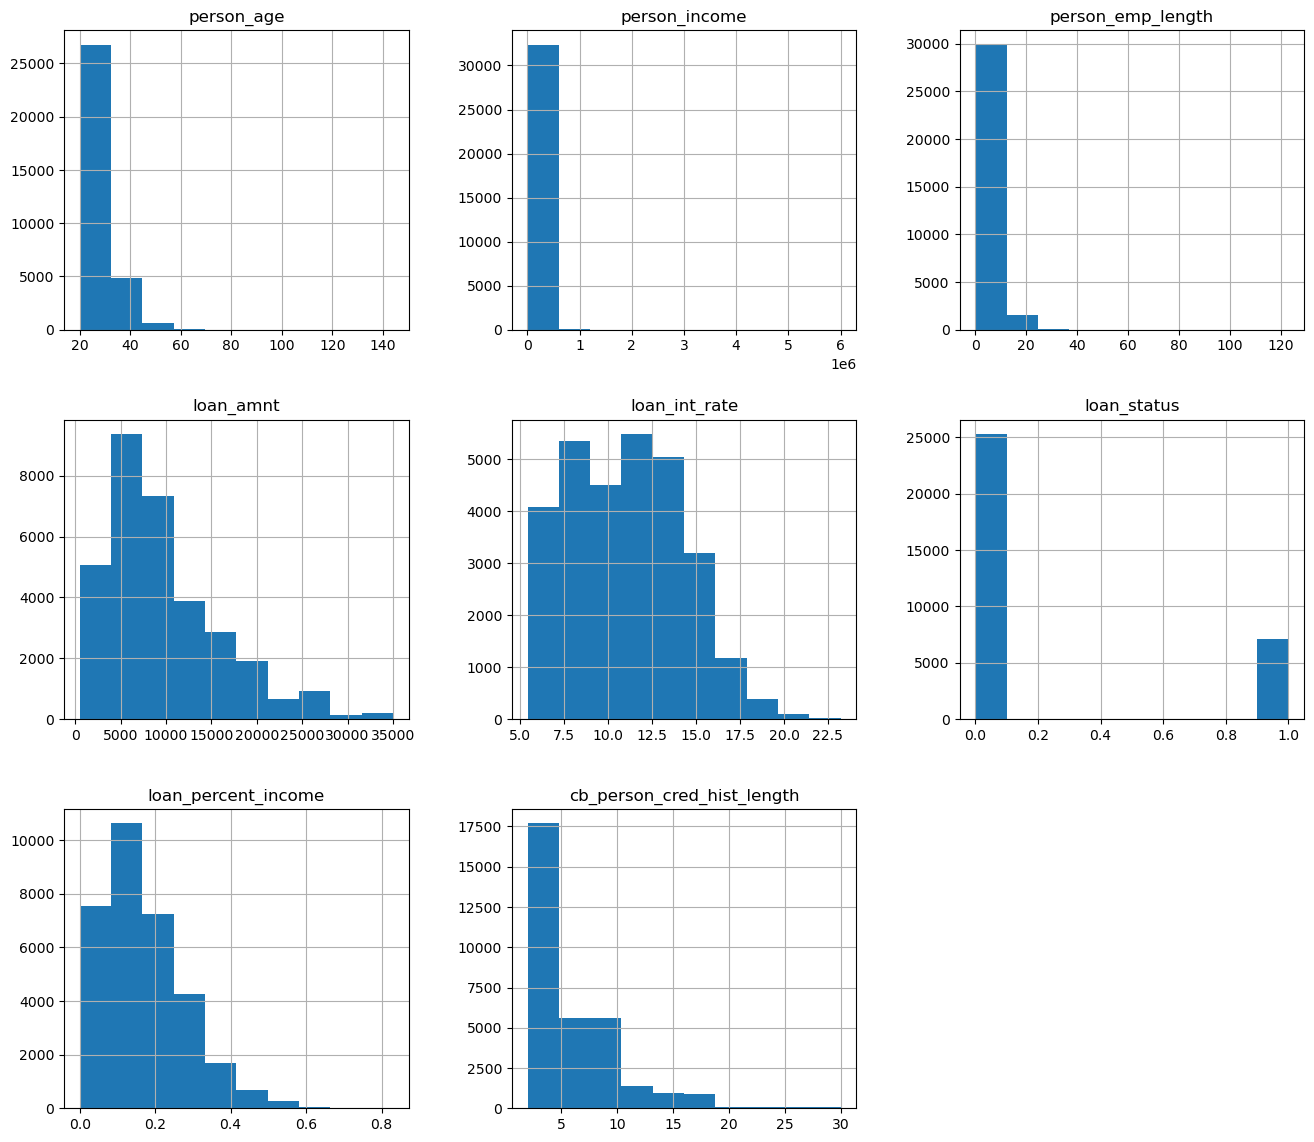

In [10]:
df.hist(figsize = (16,14))

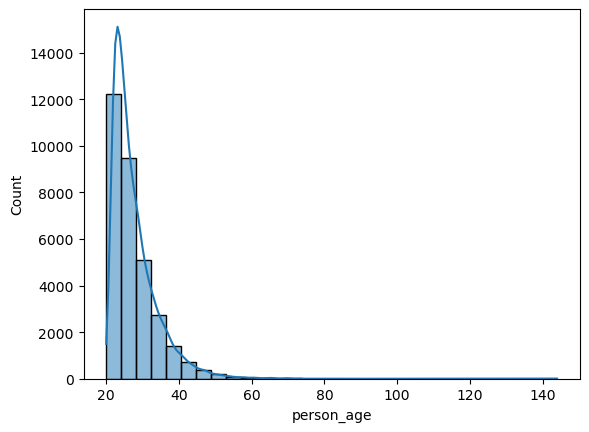

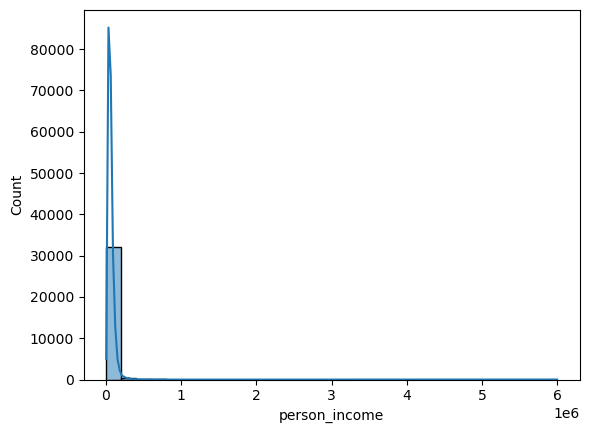

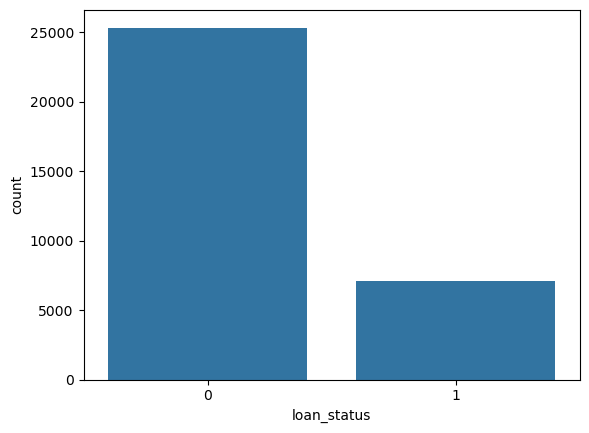

In [11]:


# Age distribution
sns.histplot(df['person_age'], bins=30, kde=True)
plt.show()

# Income distribution
sns.histplot(df['person_income'], bins=30, kde=True)
plt.show()

# Loan status count
sns.countplot(x='loan_status', data=df)
plt.show()


In [48]:
df["loan_status"].value_counts()

loan_status
0    25321
1     7088
Name: count, dtype: int64

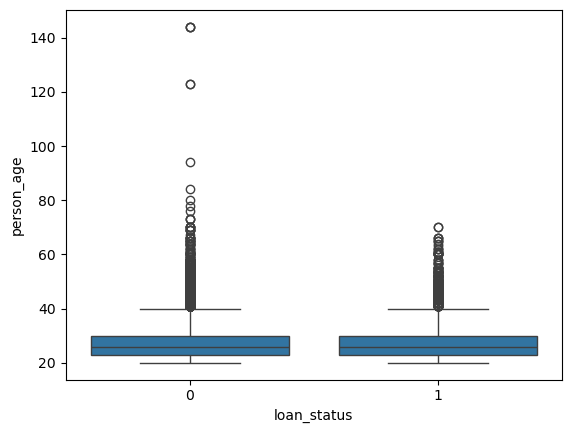

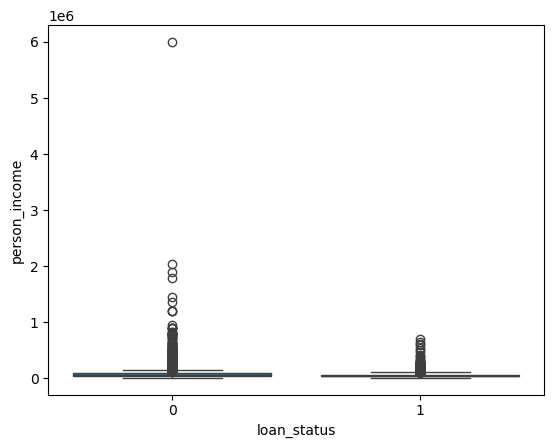

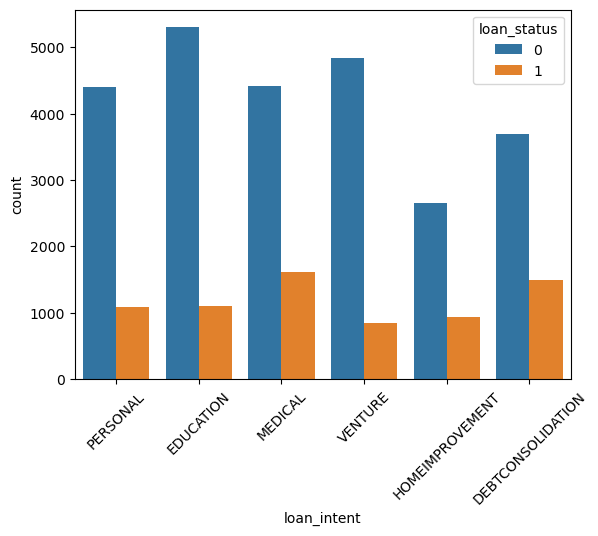

In [12]:
# Age vs Loan Status
sns.boxplot(x='loan_status', y='person_age', data=df)
plt.show()

# Income vs Loan Status
sns.boxplot(x='loan_status', y='person_income', data=df)
plt.show()

# Loan intent vs Loan Status
sns.countplot(x='loan_intent', hue='loan_status', data=df)
plt.xticks(rotation=45)
plt.show()


In [13]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32416 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32416 non-null  int64  
 1   person_income               32416 non-null  int64  
 2   person_home_ownership       32416 non-null  object 
 3   person_emp_length           31529 non-null  float64
 4   loan_intent                 32416 non-null  object 
 5   loan_grade                  32416 non-null  object 
 6   loan_amnt                   32416 non-null  int64  
 7   loan_int_rate               29321 non-null  float64
 8   loan_status                 32416 non-null  int64  
 9   loan_percent_income         32416 non-null  float64
 10  cb_person_default_on_file   32416 non-null  object 
 11  cb_person_cred_hist_length  32416 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.2+ MB


In [47]:
df["person_home_ownership"].value_counts()

person_home_ownership
RENT        16374
MORTGAGE    13366
OWN          2563
OTHER         106
Name: count, dtype: int64

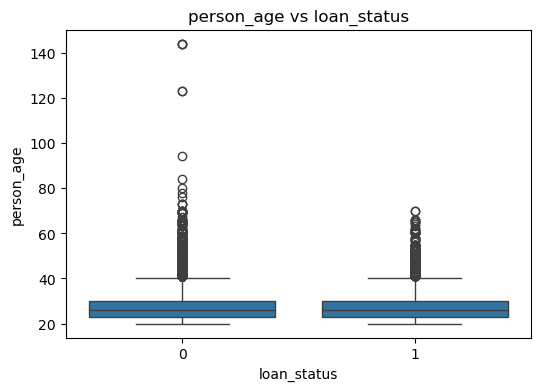

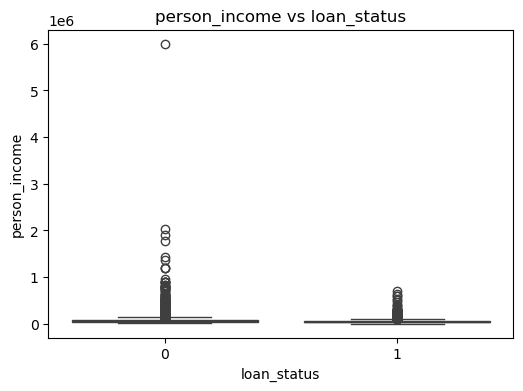

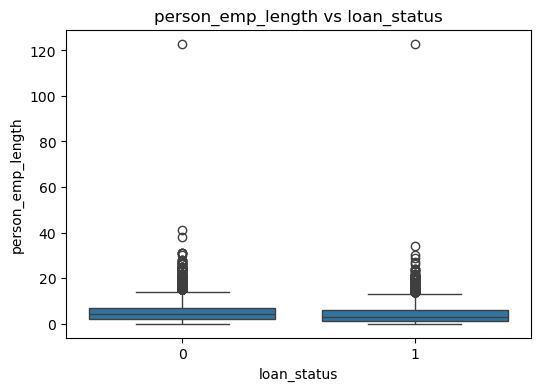

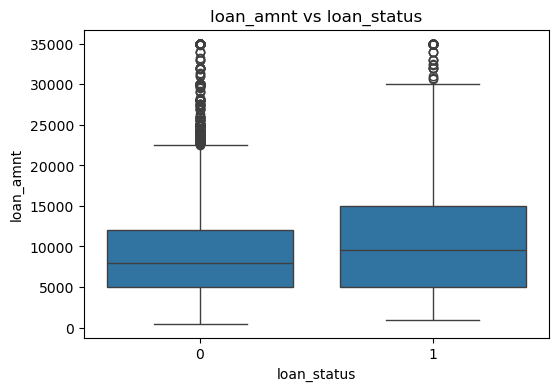

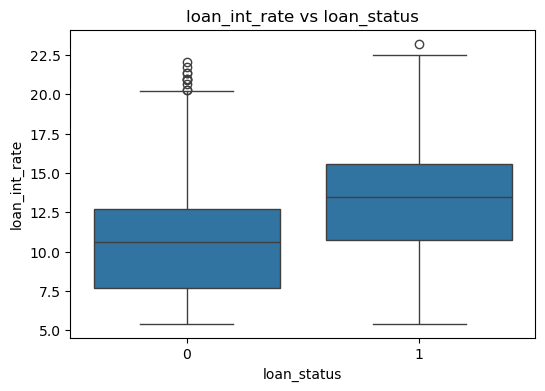

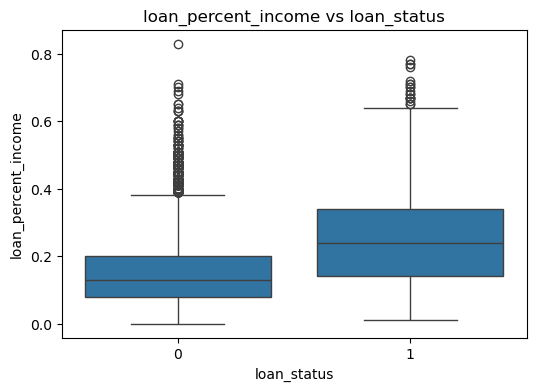

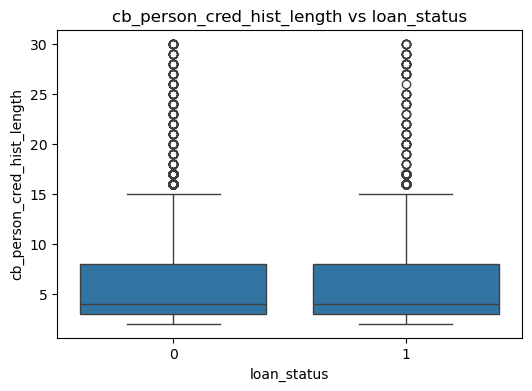

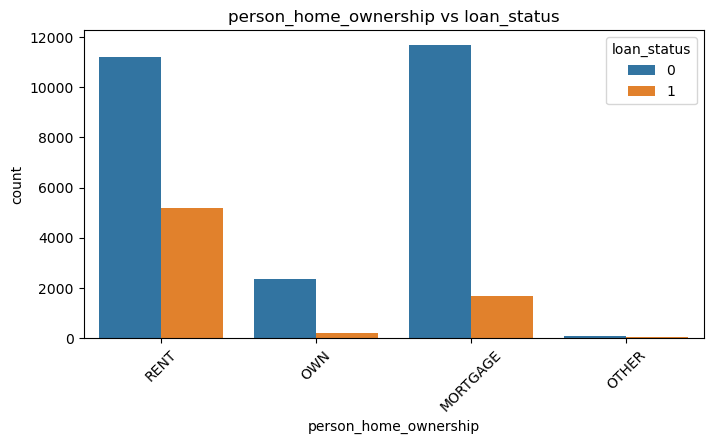

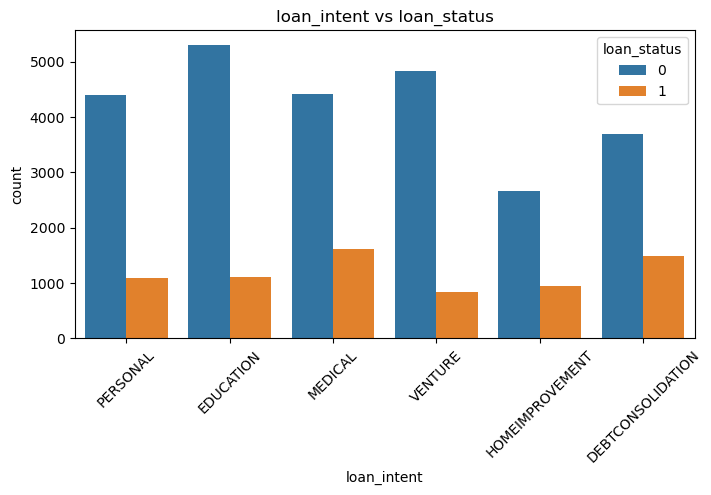

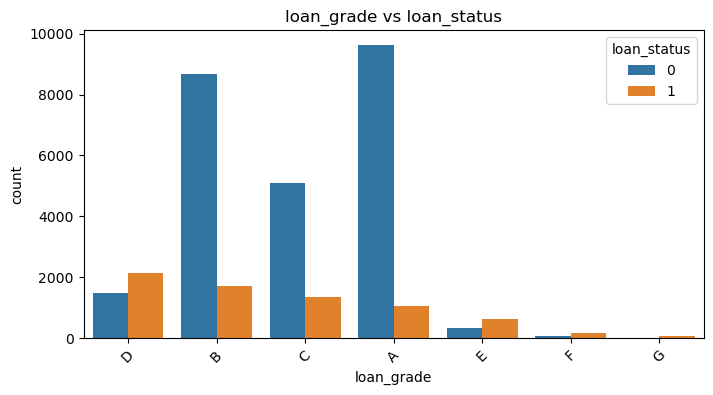

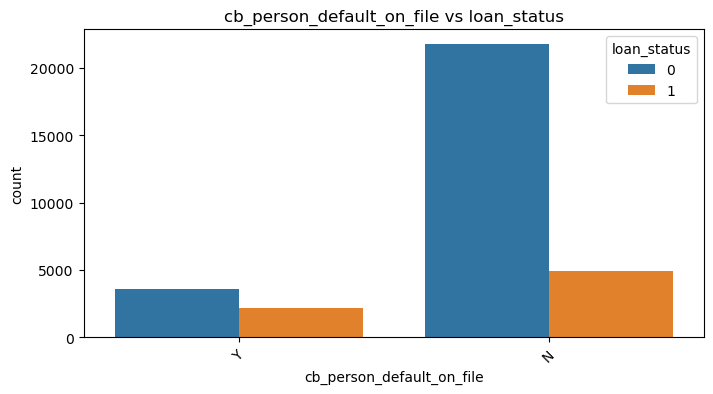

In [15]:

# Target variable
target = "loan_status"

# Separate numeric and categorical columns
num_cols = ["person_age","person_income","person_emp_length",
            "loan_amnt","loan_int_rate","loan_percent_income",
            "cb_person_cred_hist_length"]

cat_cols = ["person_home_ownership","loan_intent","loan_grade",
            "cb_person_default_on_file"]

# Numeric features vs target
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[target], y=df[col])
    plt.title(f"{col} vs {target}")
    plt.show()

# Categorical features vs target
for col in cat_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(x=col, hue=target, data=df)
    plt.title(f"{col} vs {target}")
    plt.xticks(rotation=45)
    plt.show()


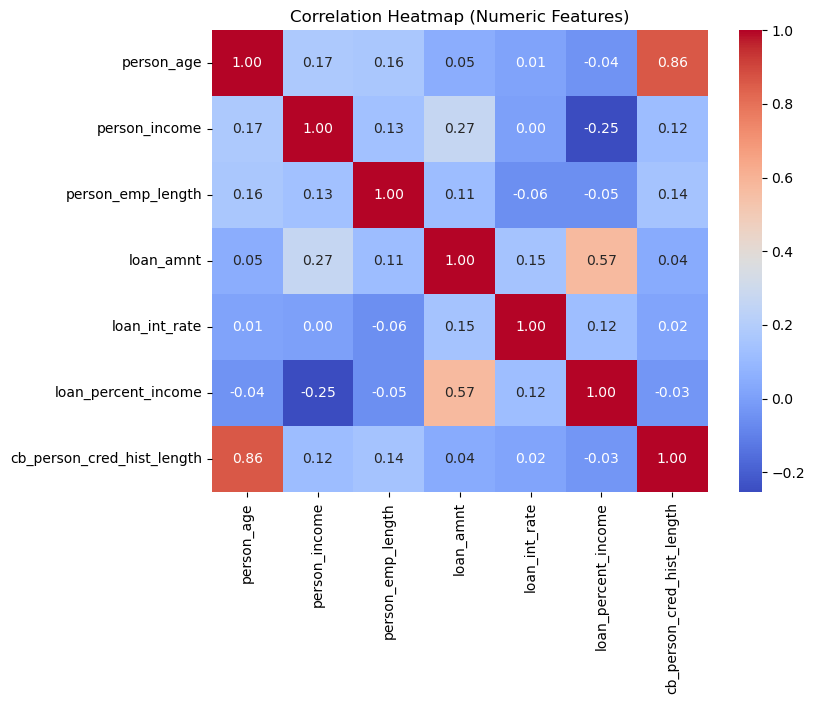

In [16]:
# Correlation heatmap for numeric features
cols_n = ["person_age", "person_income", "person_emp_length" , "loan_amnt" , "loan_int_rate" , "loan_percent_income" , "cb_person_cred_hist_length"]
plt.figure(figsize=(8,6))
sns.heatmap(df[cols_n].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Numeric Features)")
plt.show()
 


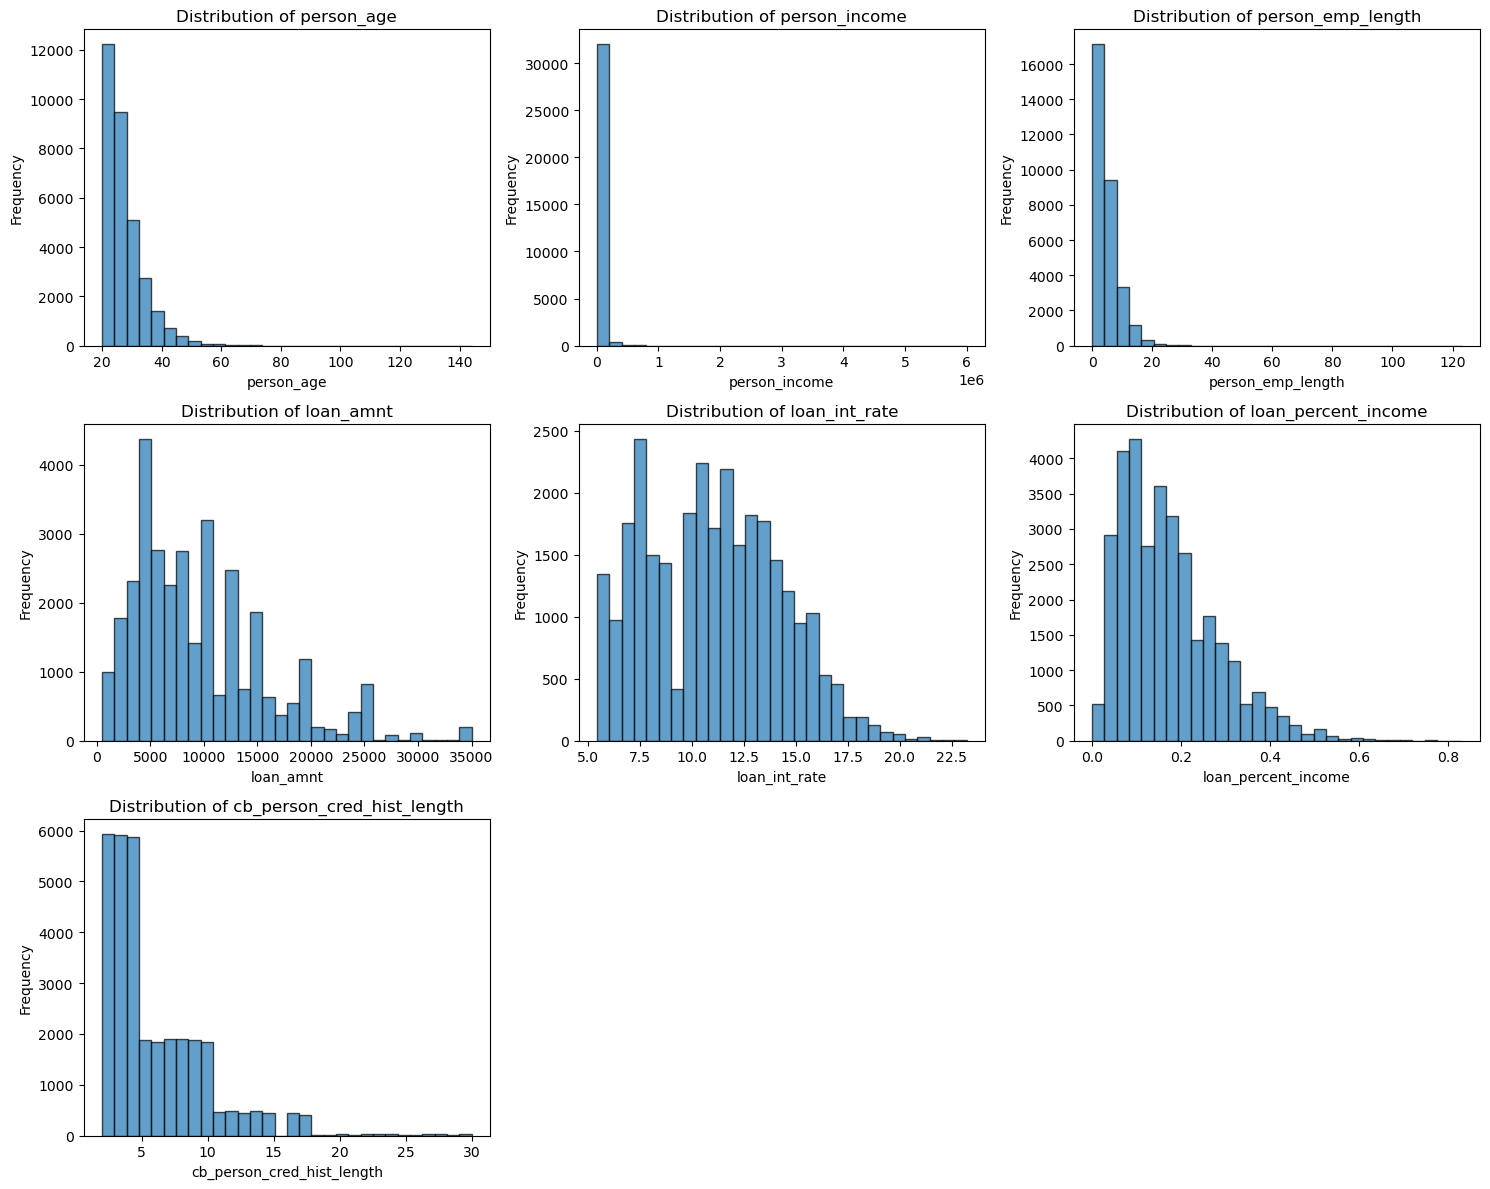

In [17]:

numerical_cols = ['person_age', 'person_income', 'person_emp_length', 
                  'loan_amnt', 'loan_int_rate', 'loan_percent_income', 
                  'cb_person_cred_hist_length']

# Histograms
plt.figure(figsize=(15,12))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 3, i)
    plt.hist(df[col].dropna(), bins=30, edgecolor='black', alpha=0.7)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


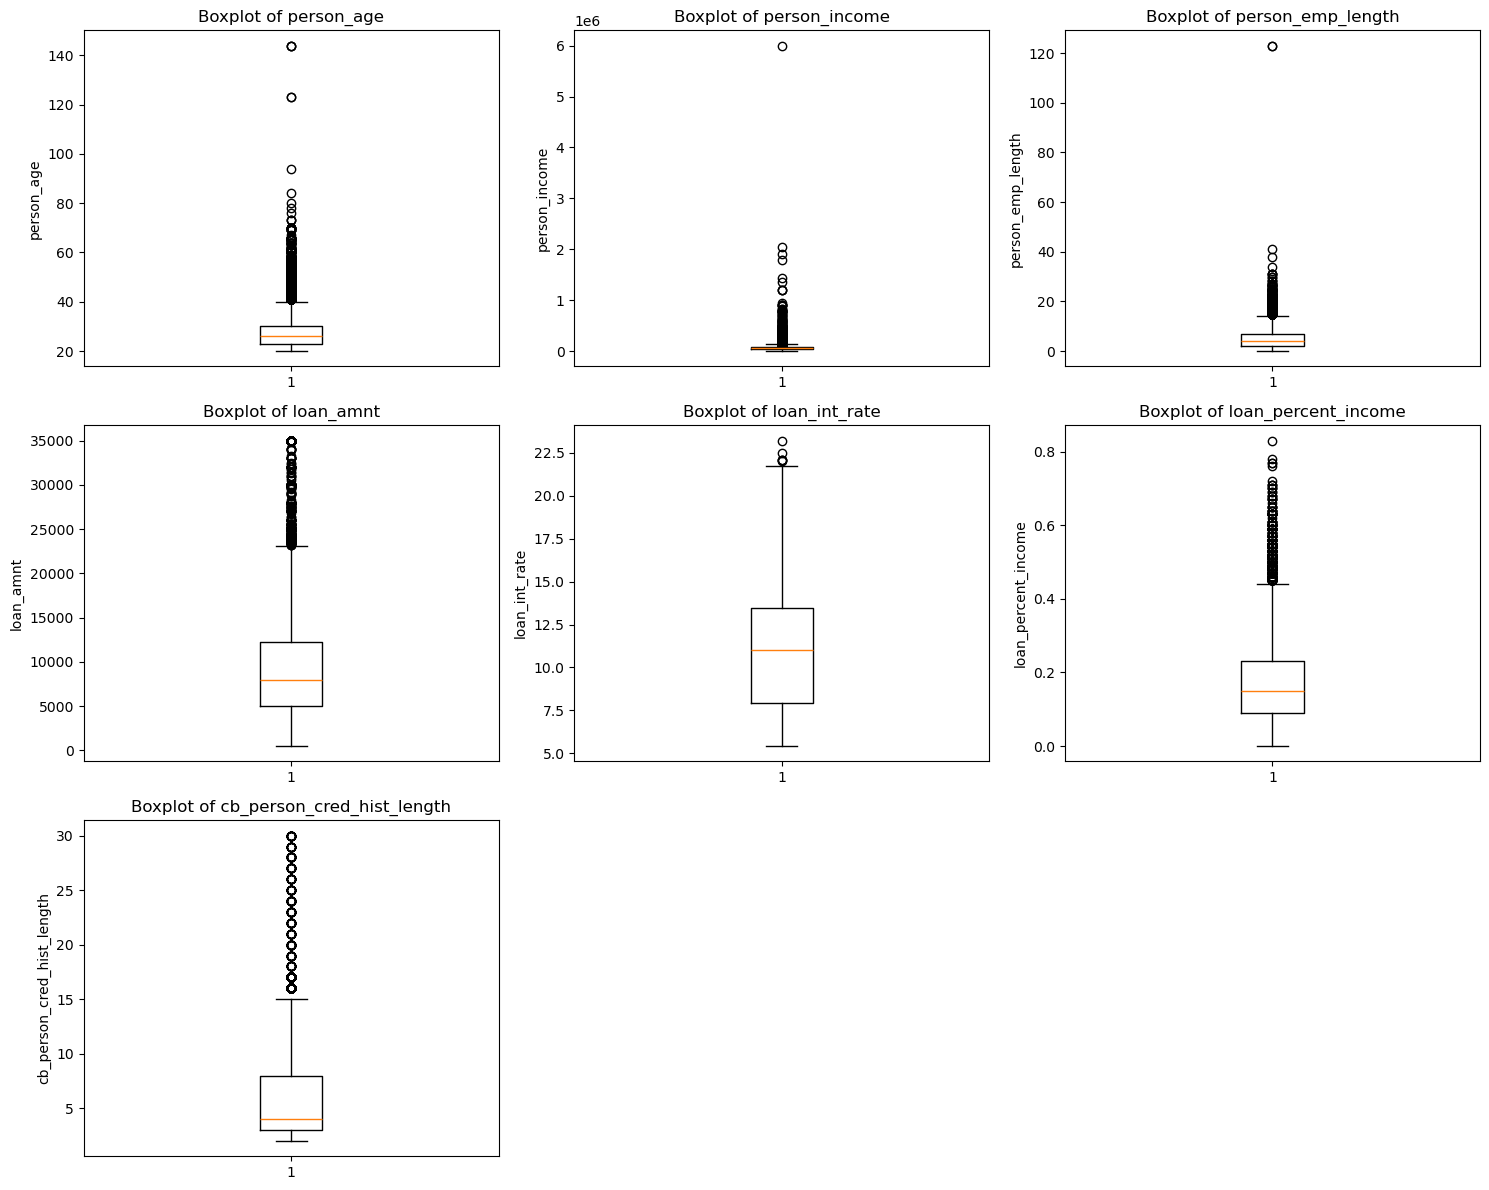

In [18]:

plt.figure(figsize=(15,12))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 3, i)
    plt.boxplot(df[col].dropna())
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()


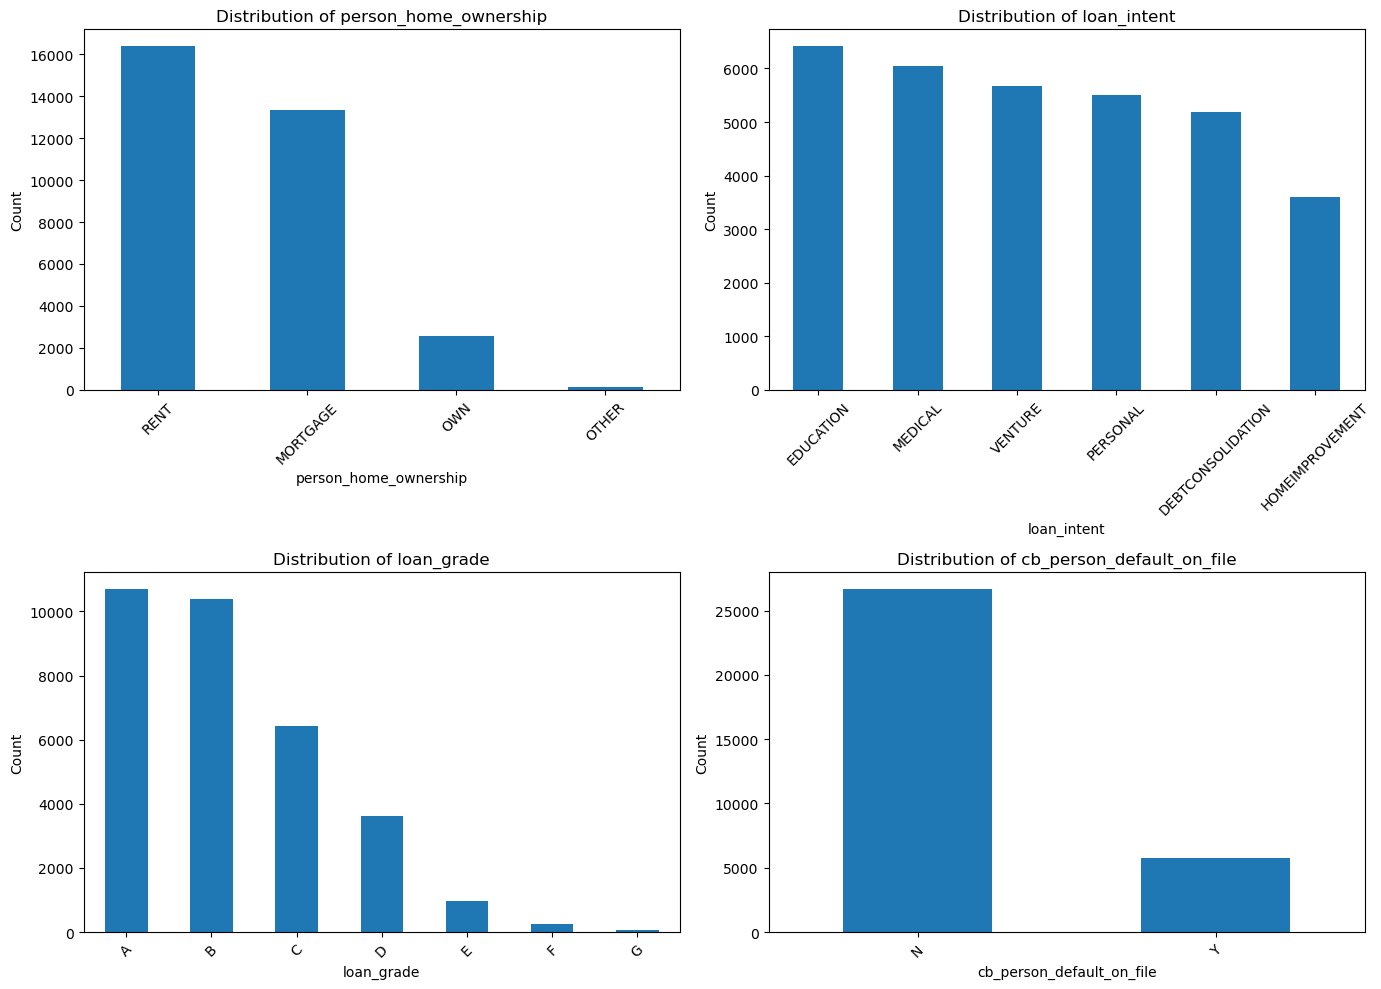

In [19]:

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, col in enumerate(categorical_cols):
    df[col].value_counts().plot(kind='bar', ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

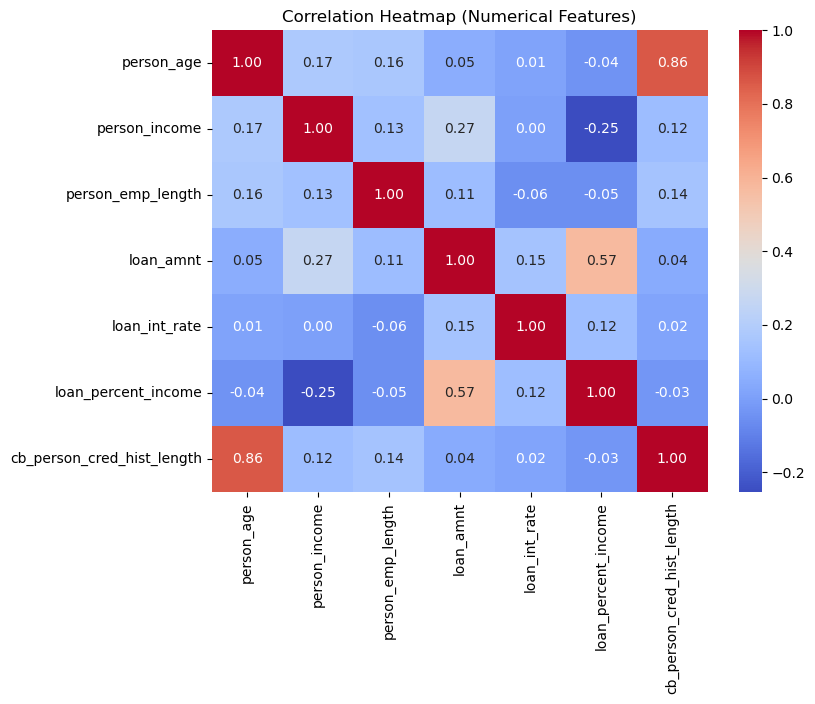

In [20]:
# Correlation heatmap for numerical features
plt.figure(figsize=(8,6))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Numerical Features)")
plt.show()


In [21]:
df.select_dtypes(include=['object', 'category']).nunique()

person_home_ownership        4
loan_intent                  6
loan_grade                   7
cb_person_default_on_file    2
dtype: int64

In [22]:
# Droping rows where employment length > age

print("Before : " , df.shape)

df = df.drop(df[df['person_emp_length'] > df['person_age']].index)


print("After : ",df.shape)


Before :  (32416, 12)
After :  (32414, 12)


In [23]:
# Droping rows where age > 100
print("Before : " , df.shape)

df = df.drop(df[df['person_age'] > 100].index)

# Verify
print("After : " , df.shape)


Before :  (32414, 12)
After :  (32409, 12)


In [24]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              887
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3094
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

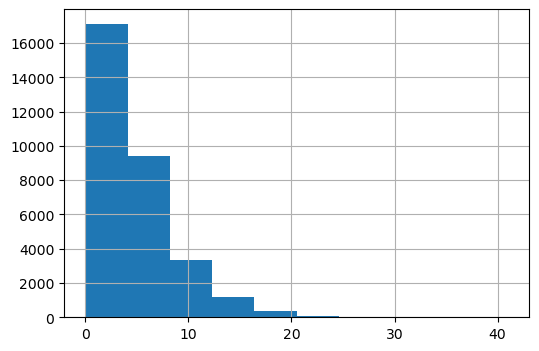

In [25]:
df["person_emp_length"].hist(figsize = (6,4))
plt.show()

In [26]:
df["person_emp_length"].skew()

np.float64(1.249611757972107)

In [27]:
# Median imputation for person_emp_length
df['person_emp_length'].fillna(df['person_emp_length'].median(), inplace=True)


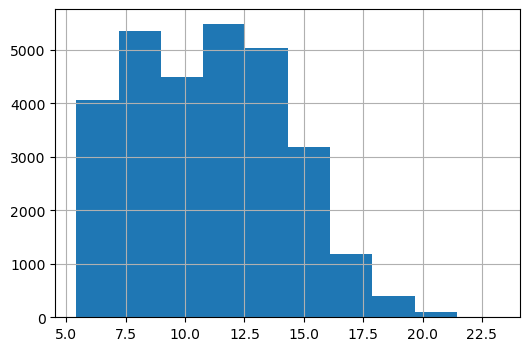

In [28]:
df["loan_int_rate"].hist(figsize=(6,4))
plt.show()

In [29]:
df["loan_int_rate"].skew()

np.float64(0.20713303244358824)

In [30]:
# Filling with mean because the skewness is small ( - 0.5 to +0.5 is approximate symmatry)
df['loan_int_rate'].fillna(df['loan_int_rate'].mean(), inplace=True)


In [31]:
df.isnull().sum().any()

np.False_

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder , OneHotEncoder , LabelEncoder , StandardScaler

from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Train Test Split

In [35]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']

num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object'] ).columns.tolist()
cat_cols


['person_home_ownership',
 'loan_intent',
 'loan_grade',
 'cb_person_default_on_file']

In [36]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

## Model Building

In [37]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

In [38]:
model = Pipeline([
    ('prep', preprocessor),
   
    ('logreg', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])


In [39]:
# Fit
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

## Evaluation

In [40]:
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

accuracy = accuracy_score(y_pred , y_test)
accuracy


0.8076021226706158

In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,classification_report ,  confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression

In [43]:



logreg_pipe = Pipeline([
    ('prep', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('logreg', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

logreg_pipe.fit(X_train, y_train)
y_pred = logreg_pipe.predict(X_test)
y_prob = logreg_pipe.predict_proba(X_test)[:,1]

print("Logistic Regression")
print("F1-Score :", f1_score(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))  
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n Classification report  : \n" , classification_report(y_test, y_pred))

Logistic Regression
F1-Score : 0.6372298396467581
Accuracy: 0.8073553005059855
Recall   : 0.7737020316027088
ROC-AUC: 0.8707103567561245
Confusion Matrix:
 [[5171 1160]
 [ 401 1371]]

 Classification report  : 
               precision    recall  f1-score   support

           0       0.93      0.82      0.87      6331
           1       0.54      0.77      0.64      1772

    accuracy                           0.81      8103
   macro avg       0.73      0.80      0.75      8103
weighted avg       0.84      0.81      0.82      8103



In [44]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([
    ('prep', preprocessor),
    
    ('rf', RandomForestClassifier(class_weight='balanced', random_state=42))
])

rf_pipe.fit(X_train, y_train)
y_pred = rf_pipe.predict(X_test)
y_prob = rf_pipe.predict_proba(X_test)[:,1]

print("Random Forest")
print("F1-Score :", f1_score(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))  
print("F1-Score :", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n Classification report  : \n" , classification_report(y_test, y_pred))

Random Forest
F1-Score : 0.8287292817679558
Accuracy: 0.9349623596198938
Recall   : 0.7195259593679458
F1-Score : 0.8287292817679558
ROC-AUC: 0.9325163042722524
Confusion Matrix:
 [[6301   30]
 [ 497 1275]]

 Classification report  : 
               precision    recall  f1-score   support

           0       0.93      1.00      0.96      6331
           1       0.98      0.72      0.83      1772

    accuracy                           0.93      8103
   macro avg       0.95      0.86      0.89      8103
weighted avg       0.94      0.93      0.93      8103



In [45]:
from sklearn.svm import SVC

svm_pipe = Pipeline([
    ('prep', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('svm', SVC(probability=True, class_weight='balanced', random_state=42))
])

svm_pipe.fit(X_train, y_train)
y_pred = svm_pipe.predict(X_test)
y_prob = svm_pipe.predict_proba(X_test)[:,1]

print("SVM")
print("F1-Score :", f1_score(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))  
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n Classification report  : \n" , classification_report(y_test, y_pred))

SVM
F1-Score : 0.7540061849873488
Accuracy: 0.8920153029742071
Recall   : 0.7567720090293454
ROC-AUC: 0.9103620687626509
Confusion Matrix:
 [[5887  444]
 [ 431 1341]]

 Classification report  : 
               precision    recall  f1-score   support

           0       0.93      0.93      0.93      6331
           1       0.75      0.76      0.75      1772

    accuracy                           0.89      8103
   macro avg       0.84      0.84      0.84      8103
weighted avg       0.89      0.89      0.89      8103



In [61]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipe = Pipeline([
    ('prep', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('knn', KNeighborsClassifier())
])

knn_pipe.fit(X_train, y_train)
y_pred = knn_pipe.predict(X_test)

print("KNN")
print("F1-Score :", f1_score(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))  
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\n Classification report  : \n" , classification_report(y_test, y_pred))

KNN
F1-Score : 0.6410803127221038
Accuracy: 0.8130322102924843
Recall   : 0.7635440180586908
Confusion Matrix:
 [[5235 1096]
 [ 419 1353]]

 Classification report  : 
               precision    recall  f1-score   support

           0       0.93      0.83      0.87      6331
           1       0.55      0.76      0.64      1772

    accuracy                           0.81      8103
   macro avg       0.74      0.80      0.76      8103
weighted avg       0.84      0.81      0.82      8103



In [62]:
from sklearn.tree import DecisionTreeClassifier

dt_pipe = Pipeline([
    ('prep', preprocessor),
    
    ('dt', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])

dt_pipe.fit(X_train, y_train)
y_pred = dt_pipe.predict(X_test)
y_prob = dt_pipe.predict_proba(X_test)[:,1]

print("Decision Tree")
print("F1-Score :", f1_score(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))  
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("\n Classification report  : \n" , classification_report(y_test, y_pred))

Decision Tree
F1-Score : 0.7534549474847982
Accuracy: 0.8899173145748488
Recall   : 0.7691873589164786
ROC-AUC: 0.8464480468567546
Confusion Matrix:
 [[5848  483]
 [ 409 1363]]
              precision    recall  f1-score   support

           0       0.93      0.92      0.93      6331
           1       0.74      0.77      0.75      1772

    accuracy                           0.89      8103
   macro avg       0.84      0.85      0.84      8103
weighted avg       0.89      0.89      0.89      8103


 Classification report  : 
               precision    recall  f1-score   support

           0       0.93      0.92      0.93      6331
           1       0.74      0.77      0.75      1772

    accuracy                           0.89      8103
   macro avg       0.84      0.85      0.84      8103
weighted avg       0.89      0.89      0.89      8103



## Hyperparameter  Tuning

In [46]:
from sklearn.model_selection import GridSearchCV

# For RandomForest

param_grid = {
    'rf__n_estimators': [100, 200, 300],        
    'rf__max_depth': [None, 10, 20, 30],        
    'rf__min_samples_split': [2, 5, 10],        
    'rf__min_samples_leaf': [1, 2, 4],          
}

grid_search = GridSearchCV(
    rf_pipe,
    param_grid,
    scoring='recall',       
    n_jobs=-1,           
    verbose=2
)

grid_search.fit(X_train, y_train)
print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


KeyboardInterrupt: 

In [ ]:
from sklearn.ensemble import RandomForestClassifier

grid_search = GridSearchCV(
    rf_pipe,
    param_grid,
    scoring='recall',     
    n_jobs=-1,           
    verbose=2
)


best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print("Test F1:", f1_score(y_test, y_pred))


# Save Model

In [63]:
import joblib

joblib.dump(rf_pipe, "loan_default_predict_rf_model.pkl")



['loan_default_predict_rf_model.pkl']

In [96]:
df['person_home_ownership'].value_counts()

person_home_ownership
RENT        16374
MORTGAGE    13366
OWN          2563
OTHER         106
Name: count, dtype: int64

In [121]:
print(df.columns)


Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')


In [122]:
num_cols = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'   # <-- must match dataset spelling
]


In [124]:
# Separate features and target
X = df.drop('loan_status', axis=1)
y = df['loan_status']

# Detect numeric and categorical columns from X only
num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()


In [128]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

model = Pipeline([
    ('prep', preprocessor),
   
    ('logreg', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

# Train/test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

# Fit
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)


In [129]:
y_pred

array([0, 1, 1, ..., 0, 0, 1], shape=(8103,))

In [1]:
from sklearn.metrics import accuracy 

accuracy = accuracy_score(y_pred , y_test)

ImportError: cannot import name 'accuracy' from 'sklearn.metrics' (C:\Users\Rudrakanta\anaconda3\Lib\site-packages\sklearn\metrics\__init__.py)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

# Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "SVM": SVC(probability=True, class_weight='balanced', random_state=42),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42)
}

results = {}

for name, clf in models.items():
    pipe = Pipeline([
        ('prep', preprocessor),   # scaling + encoding
        ('smote', SMOTE(random_state=42)),  # balance classes
        ('model', clf)
    ])
    
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:,1] if hasattr(pipe, "predict_proba") else None
    
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob) if y_prob is not None else None
    
    results[name] = {"Accuracy": acc, "ROC-AUC": auc}
    print(f"{name}: Accuracy={acc:.3f}, ROC-AUC={auc:.3f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred), "\n")


Logistic Regression: Accuracy=0.807, ROC-AUC=0.871
Confusion Matrix:
 [[5171 1160]
 [ 401 1371]] 

Random Forest: Accuracy=0.932, ROC-AUC=0.931
Confusion Matrix:
 [[6239   92]
 [ 456 1316]] 



In [ ]:
models = {
    "LogReg": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "RandomForest": RandomForestClassifier(class_weight='balanced'),
    "SVM": SVC(probability=True, class_weight='balanced'),
    "KNN": KNeighborsClassifier(),
    "DecisionTree": DecisionTreeClassifier(class_weight='balanced')
}

results = {}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    results[name] = pipe.score(X_test, y_test)

print(results)